## **SoftMax/Multinomial Regression**

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score,confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [61]:
data = sns.load_dataset('iris')

In [62]:
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [63]:
encoder = LabelEncoder()
data['species'] = encoder.fit_transform(data['species'])

In [64]:
x = data.iloc[:,0:2]
y = data.iloc[:,-1]

In [65]:
x.head()

,sepal_length,sepal_width
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6


In [66]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: species, dtype: int64

In [67]:
y.unique()

array([0, 1, 2])

In [68]:
x_train,x_test , y_train ,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [69]:
clf = LogisticRegression()
clf.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [70]:
y_pred = clf.predict(x_test)

In [71]:
print('accuracy_score: ',accuracy_score(y_test,y_pred))

accuracy_score:  0.9


In [72]:
pd.DataFrame(confusion_matrix(y_test,y_pred))

,0,1,2
0,10,0,0
1,0,7,2
2,0,1,10


In [73]:
clf.predict_proba(x_test)

array([[2.29668297e-02, 5.45331273e-01, 4.31701897e-01],
       [7.31126359e-01, 1.35375225e-01, 1.33498416e-01],
       [2.25226254e-05, 1.63333592e-01, 8.36643886e-01],
       [4.50334476e-02, 5.45566190e-01, 4.09400363e-01],
       [1.62111339e-03, 3.43221289e-01, 6.55157597e-01],
       [6.84163205e-01, 2.09649289e-01, 1.06187506e-01],
       [1.65430347e-01, 5.74057192e-01, 2.60512462e-01],
       [2.75388463e-03, 2.70356947e-01, 7.26889168e-01],
       [2.23630123e-03, 6.30749512e-01, 3.67014187e-01],
       [4.74782791e-02, 6.32891341e-01, 3.19630380e-01],
       [1.82186826e-02, 3.57299542e-01, 6.24481776e-01],
       [8.10383580e-01, 1.60909632e-01, 2.87067875e-02],
       [6.79122167e-01, 1.98390385e-01, 1.22487448e-01],
       [8.12706958e-01, 1.53838282e-01, 3.34547596e-02],
       [9.60108592e-01, 2.72526476e-02, 1.26387602e-02],
       [5.25892465e-02, 3.84965907e-01, 5.62444847e-01],
       [9.77440243e-03, 3.94106658e-01, 5.96118940e-01],
       [4.84195338e-02, 7.10193

C:\Users\LENOVO\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


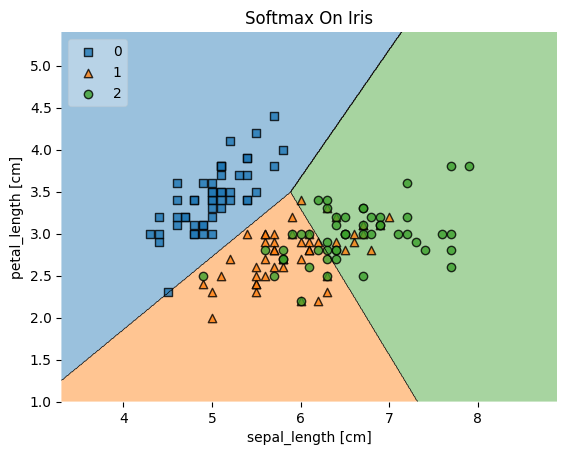

In [74]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x.values,y.values,clf,legend=2)

plt.xlabel('sepal_length [cm]')
plt.ylabel('petal_length [cm]')
plt.title('Softmax On Iris')
plt.show()